# Expected points — backtest GW1 2025-26 from 2024-25

## Load data

In [332]:
import os
import pandas as pd
# fpl_full_2025_26 path is up a directory then in data/2025-26/merged_gw_2025-26.csv
data_path = (os.path.join(os.path.dirname(os.getcwd()), 'data', '2025-26', 'merged_gw_2025-26.csv'))
fpl_full_2025_26 = pd.read_csv(data_path)
# fpl_totals_2024_25 path is up a directory then in data/2024-25/season_totals_2024-25.csv
data_path = (os.path.join(os.path.dirname(os.getcwd()), 'data', '2024-25', 'season_totals_2024-25.csv'))
fpl_totals_2024_25 = pd.read_csv(data_path)

In [333]:
# create expected points column in fpl_full_2025_26 and fill with 0
fpl_full_2025_26['xP'] = 0
# calculate total_points/38 in fpl_totals_2024_25
fpl_totals_2024_25['averaged_total_points'] = fpl_totals_2024_25['total_points'] / 38

In [334]:
# fetch code of those players in 24_25 season
players_in_24_25 = fpl_totals_2024_25['code']
players_in_25_26_gw_1 = fpl_full_2025_26[fpl_full_2025_26['round'] == 1]['code']
# new_players are those in 25_26 but not in 24_25:
new_in_25_26 = players_in_25_26_gw_1[~players_in_25_26_gw_1.isin(players_in_24_25)]

# get the full dataset of fpl_full_2025_26 but filtered for those who are new in gw 1
new_players_data = fpl_full_2025_26[(fpl_full_2025_26['code'].isin(new_in_25_26)) & (fpl_full_2025_26['round'] == 1)]

old_players_data = fpl_full_2025_26[(fpl_full_2025_26['code'].isin(players_in_24_25)) & (fpl_full_2025_26['round'] == 1)]

# assign the old_players_data expected points by mapping the code to the averaged_total_points in fpl_totals_2024_25 
code_to_xP = dict(zip(fpl_totals_2024_25['code'], fpl_totals_2024_25['averaged_total_points']))
old_players_data['xP'] = old_players_data['code'].map(code_to_xP)


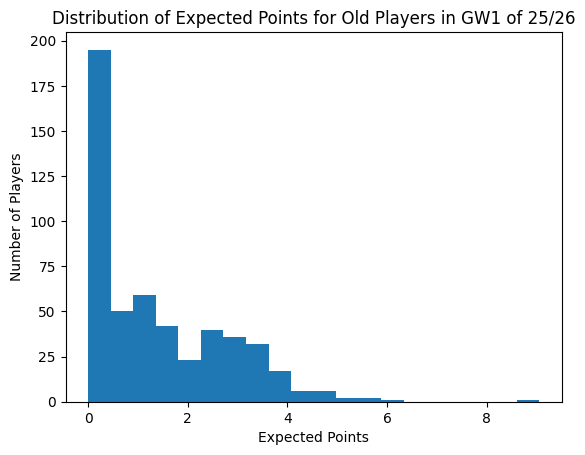

In [335]:
# output histogram of expected points for old players
import matplotlib.pyplot as plt
plt.hist(old_players_data['xP'], bins=20)
plt.xlabel('Expected Points')
plt.ylabel('Number of Players')
plt.title('Distribution of Expected Points for Old Players in GW1 of 25/26')
plt.show()

## Baseline

### Lookback 5

In [336]:
# Rolling Window (5): For each player, calculate the average points per game over the previous 5 gameweeks (or fewer if less than 5 gameweeks of data are available). This gives a dynamic expected points value that evolves throughout the season based on recent performance.
LOOKBACK = 5

# Pivot to wide: rows=round, cols=code, values=total_points.
# shift(1) so round N's expected value uses rounds up to N-1 only (no leakage).
wide = fpl_full_2025_26.pivot_table(index="round", columns="code", values="total_points")
rolled = wide.shift(1).rolling(window=LOOKBACK, min_periods=1).mean()

# Unpivot back to long form.
exp_in_season = (
    rolled.stack()
    .reset_index()
    .rename(columns={0: "exp_pts_in_season"})
)

# GW1 prior: 2024-25 per-game average (total / 38).
code_to_prior = dict(zip(fpl_totals_2024_25["code"], fpl_totals_2024_25["averaged_total_points"]))

# Merge expected points onto the full GW dataset.
df = fpl_full_2025_26.merge(exp_in_season, on=["round", "code"], how="left")

# For GW1, there's no in-season history — overwrite with 2024-25 prior.
gw1 = df["round"] == 1
df.loc[gw1, "exp_pts_in_season"] = df.loc[gw1, "code"].map(code_to_prior)

# Fallback for players with no history at all: use per-round positional average.
pos_avg = df.groupby(["round", "position"])["exp_pts_in_season"].transform("mean")
df["xP_rw_5"] = df["exp_pts_in_season"].fillna(pos_avg)

print(f"Coverage: {df['xP_rw_5'].notna().mean():.1%} of player-GW rows have an expected points value")
df[["round", "web_name", "position", "team_name", "total_points", "xP_rw_5"]].head(20)


Coverage: 100.0% of player-GW rows have an expected points value


,round,web_name,position,team_name,total_points,xP_rw_5
0,1,Raya,GKP,Arsenal,10,3.736842
1,1,Arrizabalaga,GKP,Arsenal,0,2.789474
2,1,Hein,GKP,Arsenal,0,0.000000
3,1,Setford,GKP,Arsenal,0,0.000000
4,1,Gabriel,DEF,Arsenal,6,3.078947
5,1,Saliba,DEF,Arsenal,9,3.421053
6,1,Calafiori,DEF,Arsenal,13,1.026316
7,1,J.Timber,DEF,Arsenal,0,3.000000
8,1,Kiwior,DEF,Arsenal,0,1.131579
9,1,Lewis-Skelly,DEF,Arsenal,0,0.973684


In [337]:
# verify computation
# test with web_name == 'Raya'
# output all instances with web_name 'Raya'
name_to_check = 'Raya'
df_to_check = df[df['web_name'] == name_to_check]
cols_to_keep = ['round', 'total_points', 'xP_rw_5' , 'web_name'] 
print(df_to_check[cols_to_keep])


       round  total_points    xP_rw_5 web_name
0          1            10   3.736842     Raya
690        2             6  10.000000     Raya
1395       3             2   8.000000     Raya
2107       4             6   6.000000     Raya
2847       5             2   6.000000     Raya
3588       6             2   5.200000     Raya
4330       7             6   3.600000     Raya
5073       8             6   3.600000     Raya
5818       9             6   4.400000     Raya
6564      10             6   4.400000     Raya
7311      11             1   5.200000     Raya
8063      12             2   5.000000     Raya
8818      13             3   4.200000     Raya
9573      14             6   3.600000     Raya
10331     15             2   3.600000     Raya
11090     16             2   2.800000     Raya
11850     17             7   3.000000     Raya
12620     18             2   4.000000     Raya
13395     19             2   3.800000     Raya
14175     20             1   3.000000     Raya
14965     21 

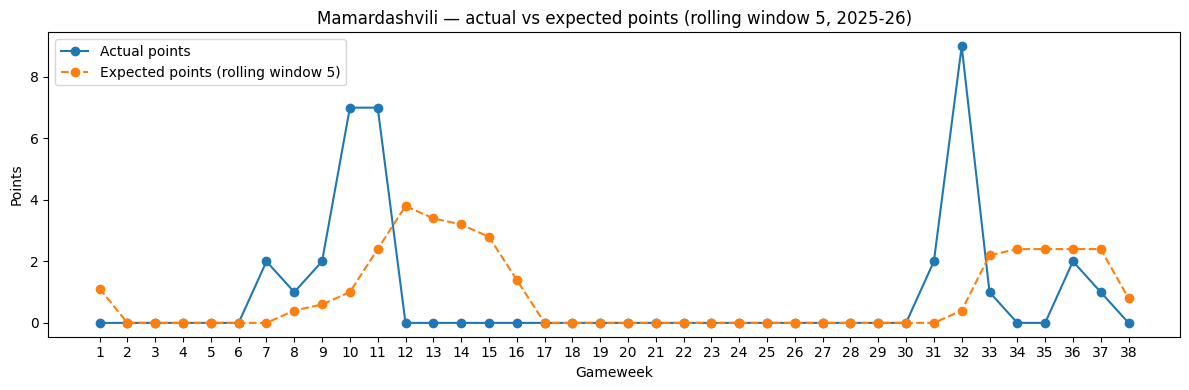

In [338]:
random_player = df.sample(1)
player_code = random_player["code"].values[0]
player_name = random_player["web_name"].values[0]

player_df = df[df["code"] == player_code].sort_values("round")

plt.figure(figsize=(12, 4))
plt.plot(player_df["round"], player_df["total_points"], marker="o", label="Actual points")
plt.plot(player_df["round"], player_df["xP_rw_5"], marker="o", linestyle="--", label="Expected points (rolling window 5)")
plt.xlabel("Gameweek")
plt.ylabel("Points")
plt.title(f"{player_name} — actual vs expected points (rolling window 5, 2025-26)")
plt.legend()
plt.xticks(range(1, 39))
plt.tight_layout()
plt.show()

### Lookback 1

In [339]:
# Window-1 model: expected points = last gameweek's actual points.
LOOKBACK = 1

wide1 = fpl_full_2025_26.pivot_table(index="round", columns="code", values="total_points")
rolled1 = wide1.shift(1).rolling(window=LOOKBACK, min_periods=1).mean()

exp_in_season_1 = (
    rolled1.stack()
    .reset_index()
    .rename(columns={0: "exp_pts_in_season_1"})
)

# Merge into existing df (which already has xP_rw_5).
df = df.merge(exp_in_season_1, on=["round", "code"], how="left")

# GW1: use same 2024-25 prior.
gw1 = df["round"] == 1
df.loc[gw1, "exp_pts_in_season_1"] = df.loc[gw1, "code"].map(code_to_prior)

pos_avg_1 = df.groupby(["round", "position"])["exp_pts_in_season_1"].transform("mean")
df["xP_rw_1"] = df["exp_pts_in_season_1"].fillna(pos_avg_1)

print(f"Coverage: {df['xP_rw_1'].notna().mean():.1%}")
df[["round", "web_name", "position", "team_name", "total_points", "xP_rw_1"]].head(20)


Coverage: 100.0%


,round,web_name,position,team_name,total_points,xP_rw_1
0,1,Raya,GKP,Arsenal,10,3.736842
1,1,Arrizabalaga,GKP,Arsenal,0,2.789474
2,1,Hein,GKP,Arsenal,0,0.000000
3,1,Setford,GKP,Arsenal,0,0.000000
4,1,Gabriel,DEF,Arsenal,6,3.078947
5,1,Saliba,DEF,Arsenal,9,3.421053
6,1,Calafiori,DEF,Arsenal,13,1.026316
7,1,J.Timber,DEF,Arsenal,0,3.000000
8,1,Kiwior,DEF,Arsenal,0,1.131579
9,1,Lewis-Skelly,DEF,Arsenal,0,0.973684


In [340]:
# verify computation
# test with web_name == 'Raya'
# output all instances with web_name 'Raya'
name_to_check = 'Raya'
df_to_check = df[df['web_name'] == name_to_check]
cols_to_keep = ['round', 'total_points', 'xP_rw_1' , 'web_name'] 
print(df_to_check[cols_to_keep])


       round  total_points    xP_rw_1 web_name
0          1            10   3.736842     Raya
690        2             6  10.000000     Raya
1395       3             2   6.000000     Raya
2107       4             6   2.000000     Raya
2847       5             2   6.000000     Raya
3588       6             2   2.000000     Raya
4330       7             6   2.000000     Raya
5073       8             6   6.000000     Raya
5818       9             6   6.000000     Raya
6564      10             6   6.000000     Raya
7311      11             1   6.000000     Raya
8063      12             2   1.000000     Raya
8818      13             3   2.000000     Raya
9573      14             6   3.000000     Raya
10331     15             2   6.000000     Raya
11090     16             2   2.000000     Raya
11850     17             7   2.000000     Raya
12620     18             2   7.000000     Raya
13395     19             2   2.000000     Raya
14175     20             1   2.000000     Raya
14965     21 

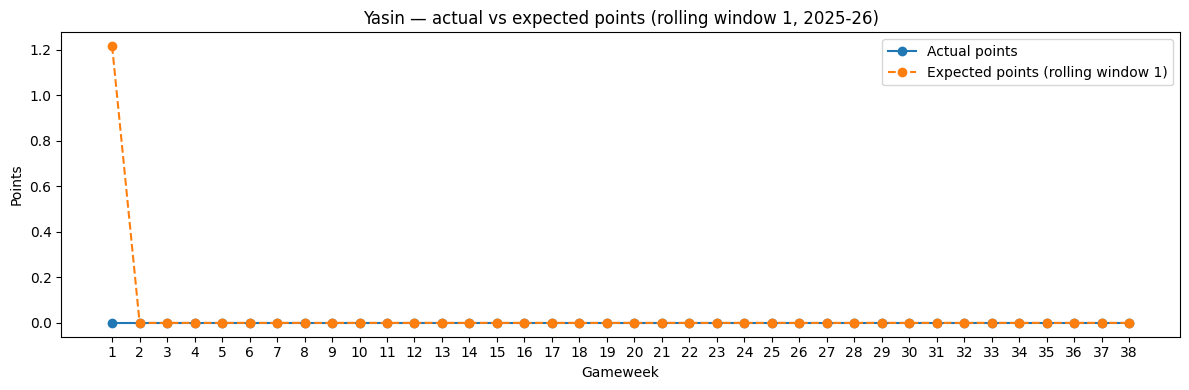

In [341]:
random_player = df.sample(1)
player_code = random_player["code"].values[0]
player_name = random_player["web_name"].values[0]

player_df = df[df["code"] == player_code].sort_values("round")

plt.figure(figsize=(12, 4))
plt.plot(player_df["round"], player_df["total_points"], marker="o", label="Actual points")
plt.plot(player_df["round"], player_df["xP_rw_1"], marker="o", linestyle="--", label="Expected points (rolling window 1)")
plt.xlabel("Gameweek")
plt.ylabel("Points")
plt.title(f"{player_name} — actual vs expected points (rolling window 1, 2025-26)")
plt.legend()
plt.xticks(range(1, 39))
plt.tight_layout()
plt.show()

In [342]:
total_points_col = df["total_points"]
xP_cols = ['xP_rw_1', 'xP_rw_5']
xP_df = df[xP_cols]
# error metrics: one summary report for each expected points column (compared to total_points)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
for col in xP_cols:
    mae = mean_absolute_error(total_points_col, xP_df[col])
    mse = mean_squared_error(total_points_col, xP_df[col])
    r2 = r2_score(total_points_col, xP_df[col])
    print(f"Metrics for {col}:")
    print(f"  Mean Absolute Error: {mae:.4f}")
    print(f"  Mean Squared Error: {mse:.4f}")
    print(f"  R^2 Score: {r2:.4f}")
# error metrics: comparison report. Compare the cols in xP_cols against each other (not against total_points) to see if they differ significantly.
for i in range(len(xP_cols)):
    for j in range(i + 1, len(xP_cols)):
        col_i = xP_cols[i]
        col_j = xP_cols[j]
        mae = mean_absolute_error(xP_df[col_i], xP_df[col_j])
        mse = mean_squared_error(xP_df[col_i], xP_df[col_j])
        r2 = r2_score(xP_df[col_i], xP_df[col_j])
        print(f"Comparison between {col_i} and {col_j}:")
        print(f"  Mean Absolute Error: {mae:.4f}")
        print(f"  Mean Squared Error: {mse:.4f}")
        print(f"  R^2 Score: {r2:.4f}")

Metrics for xP_rw_1:
  Mean Absolute Error: 1.1500
  Mean Squared Error: 6.5343
  R^2 Score: -0.1815
Metrics for xP_rw_5:
  Mean Absolute Error: 1.0540
  Mean Squared Error: 4.4718
  R^2 Score: 0.1914
Comparison between xP_rw_1 and xP_rw_5:
  Mean Absolute Error: 0.7772
  Mean Squared Error: 2.6300
  R^2 Score: 0.5101


Model                        MAE   RMSE     R²
-----------------------------------------------
Window-1 (last GW)         1.142  2.560 -0.190
Window-5 (5-GW avg)        1.044  2.108  0.193


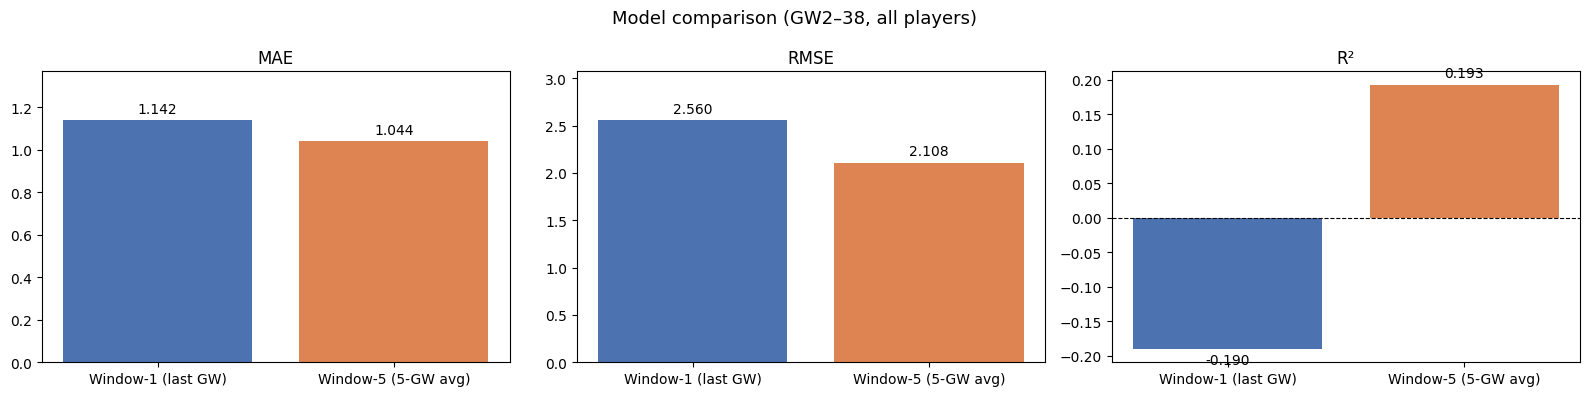

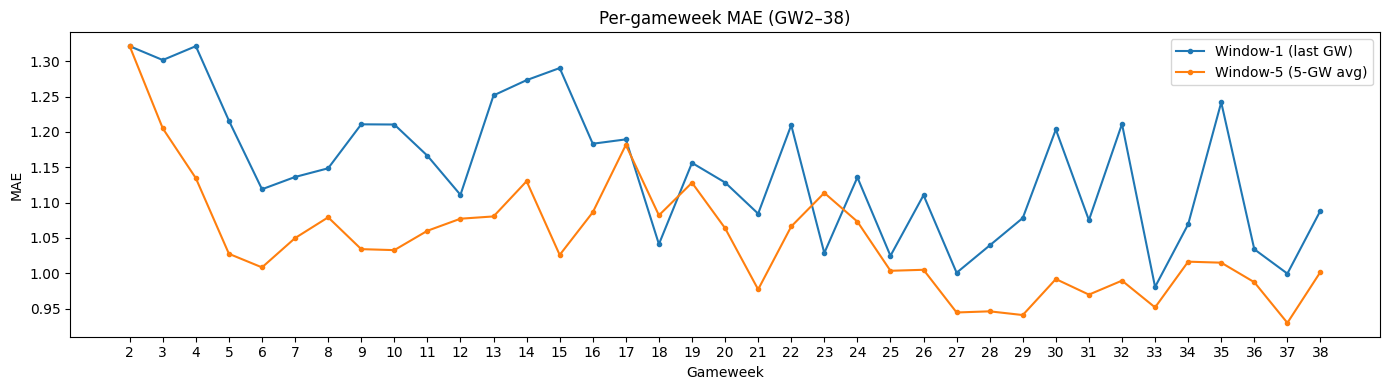

In [343]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Exclude GW1 — it uses a season-average prior, not an in-season prediction.
eval_df = df[df["round"] > 1].dropna(subset=["xP_rw_1", "xP_rw_5"])

models = {
    "Window-1 (last GW)": "xP_rw_1",
    "Window-5 (5-GW avg)": "xP_rw_5",
}

# --- Summary table ---
print(f"{'Model':<25} {'MAE':>6} {'RMSE':>6} {'R²':>6}")
print("-" * 47)
summary = {}
for label, col in models.items():
    mae  = mean_absolute_error(eval_df["total_points"], eval_df[col])
    rmse = mean_squared_error(eval_df["total_points"], eval_df[col]) ** 0.5
    r2   = r2_score(eval_df["total_points"], eval_df[col])
    summary[label] = {"MAE": mae, "RMSE": rmse, "R2": r2}
    print(f"{label:<25} {mae:>6.3f} {rmse:>6.3f} {r2:>6.3f}")

# --- Per-gameweek MAE ---
gw_mae = (
    eval_df.groupby("round")
    .apply(lambda g: {col: mean_absolute_error(g["total_points"], g[col]) for col in models.values()})
    .apply(lambda d: pd.Series(d))
)
gw_mae.columns = list(models.keys())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Bar: overall MAE / RMSE / R²
metrics_names = ["MAE", "RMSE", "R2"]
for ax, metric in zip(axes[:2], ["MAE", "RMSE"]):
    vals = [summary[l][metric] for l in models]
    bars = ax.bar(list(models.keys()), vals, color=["#4C72B0", "#DD8452"])
    ax.bar_label(bars, fmt="%.3f", padding=3)
    ax.set_title(metric)
    ax.set_ylim(0, max(vals) * 1.2)

vals_r2 = [summary[l]["R2"] for l in models]
bars = axes[2].bar(list(models.keys()), vals_r2, color=["#4C72B0", "#DD8452"])
axes[2].bar_label(bars, fmt="%.3f", padding=3)
axes[2].axhline(0, color="black", linewidth=0.8, linestyle="--")
axes[2].set_title("R²")

plt.suptitle("Model comparison (GW2–38, all players)", fontsize=13)
plt.tight_layout()
plt.show()

# Per-gameweek MAE line chart
fig, ax = plt.subplots(figsize=(14, 4))
for label in models:
    ax.plot(gw_mae.index, gw_mae[label], marker="o", markersize=3, label=label)
ax.set_xlabel("Gameweek")
ax.set_ylabel("MAE")
ax.set_title("Per-gameweek MAE (GW2–38)")
ax.legend()
ax.set_xticks(range(2, 39))
plt.tight_layout()
plt.show()


### Lookback 1-37

  10/38 done
  20/38 done
  30/38 done
Best MAE at lookback=4:  1.0433
Best R²  at lookback=23:  0.2342


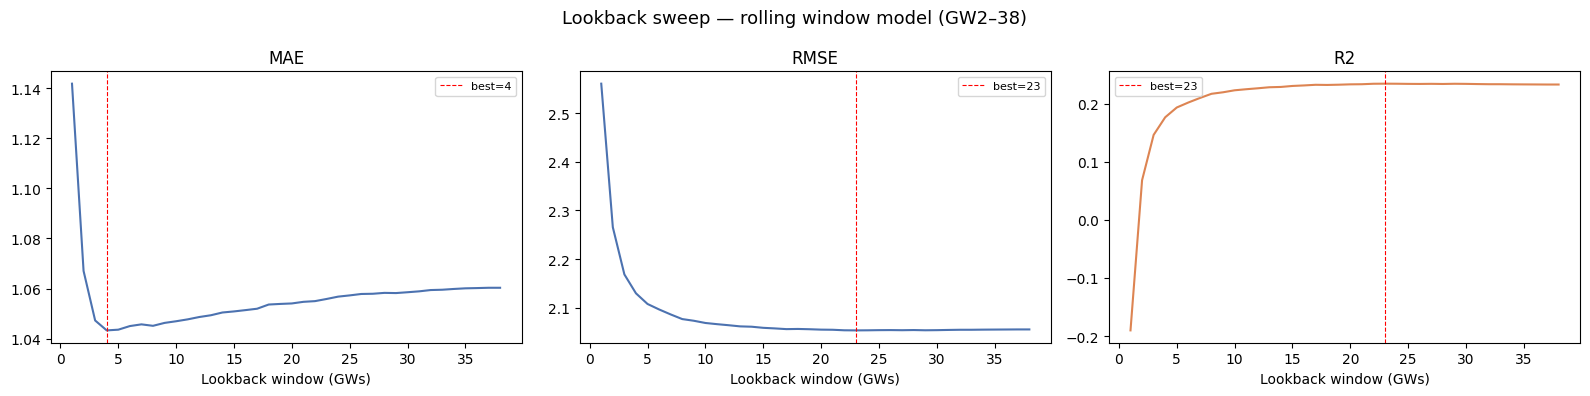

,MAE,RMSE,R2
lookback,,,
1,1.141835,2.560231,-0.190137
2,1.067022,2.265478,0.068123
3,1.047244,2.168580,0.146134
4,1.043283,2.129773,0.176421
5,1.043563,2.107913,0.193240
6,1.045007,2.096668,0.201825
7,1.045692,2.086440,0.209593
8,1.045109,2.076912,0.216796
9,1.046272,2.073454,0.219402


In [344]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Pre-compute the wide pivot once.
wide = fpl_full_2025_26.pivot_table(index="round", columns="code", values="total_points")
code_to_prior = dict(zip(fpl_totals_2024_25["code"], fpl_totals_2024_25["averaged_total_points"]))
code_to_pos = fpl_full_2025_26.drop_duplicates("code").set_index("code")["position"]

sweep_results = []
for lookback in range(1, 39):
    rolled = wide.shift(1).rolling(window=lookback, min_periods=1).mean()
    exp = rolled.stack().reset_index().rename(columns={0: "exp"})

    tmp = fpl_full_2025_26[["round", "code", "position", "total_points"]].merge(exp, on=["round", "code"], how="left")
    gw1 = tmp["round"] == 1
    tmp.loc[gw1, "exp"] = tmp.loc[gw1, "code"].map(code_to_prior)
    pos_avg = tmp.groupby(["round", "position"])["exp"].transform("mean")
    tmp["exp"] = tmp["exp"].fillna(pos_avg)

    ev = tmp[tmp["round"] > 1].dropna(subset=["exp"])
    sweep_results.append({
        "lookback": lookback,
        "MAE":  mean_absolute_error(ev["total_points"], ev["exp"]),
        "RMSE": mean_squared_error(ev["total_points"], ev["exp"]) ** 0.5,
        "R2":   r2_score(ev["total_points"], ev["exp"]),
    })
    if lookback % 10 == 0:
        print(f"  {lookback}/38 done")

sweep = pd.DataFrame(sweep_results).set_index("lookback")

best_mae  = sweep["MAE"].idxmin()
best_r2   = sweep["R2"].idxmax()
print(f"Best MAE at lookback={best_mae}:  {sweep.loc[best_mae, 'MAE']:.4f}")
print(f"Best R²  at lookback={best_r2}:  {sweep.loc[best_r2, 'R2']:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True)
for ax, metric, color in zip(axes, ["MAE", "RMSE", "R2"], ["#4C72B0", "#4C72B0", "#DD8452"]):
    ax.plot(sweep.index, sweep[metric], color=color)
    best_idx = sweep[metric].idxmin() if metric != "R2" else sweep[metric].idxmax()
    ax.axvline(best_idx, color="red", linestyle="--", linewidth=0.8, label=f"best={best_idx}")
    ax.set_title(metric)
    ax.set_xlabel("Lookback window (GWs)")
    ax.legend(fontsize=8)
plt.suptitle("Lookback sweep — rolling window model (GW2–38)", fontsize=13)
plt.tight_layout()
plt.show()

sweep


### End of Baseline
N = 5

## Iteration 1
Apply Home and Away adjustments to the lookback 5 expected points.

In [345]:
# first: analyse average points who were home vs away in the 2025-26 season
home = fpl_full_2025_26[fpl_full_2025_26['was_home'] == True]
away = fpl_full_2025_26[fpl_full_2025_26['was_home'] == False]
home_avg = home['total_points'].mean()
away_avg = away['total_points'].mean()
print(f"Average points at home: {home_avg:.3f}")
print(f"Average points away: {away_avg:.3f}")

Average points at home: 1.218
Average points away: 1.094


In [346]:
# output df columns
print(df.columns)
home_multiplier = 1.05
away_multiplier = 0.95
df['xP_rw_5_home_away_adjusted'] = df['xP_rw_5'] * df['was_home'].map({True: home_multiplier, False: away_multiplier})
print(df[['round', 'web_name', 'was_home', 'total_points', 'xP_rw_5', 'xP_rw_5_home_away_adjusted']].sample(20))

Index(['code', 'element', 'fixture', 'opponent_team', 'total_points',
       'was_home', 'kickoff_time', 'team_h_score', 'team_a_score', 'round',
       'modified', 'minutes', 'goals_scored', 'assists', 'clean_sheets',
       'goals_conceded', 'own_goals', 'penalties_saved', 'penalties_missed',
       'yellow_cards', 'red_cards', 'saves', 'bonus', 'bps', 'influence',
       'creativity', 'threat', 'ict_index', 'clearances_blocks_interceptions',
       'recoveries', 'tackles', 'defensive_contribution', 'starts',
       'expected_goals', 'expected_assists', 'expected_goal_involvements',
       'expected_goals_conceded', 'value', 'transfers_balance', 'selected',
       'transfers_in', 'transfers_out', 'player_id', 'web_name', 'team',
       'team_name', 'position', 'opponent_team_name', 'team_short',
       'opponent_team_short', 'xP', 'exp_pts_in_season', 'xP_rw_5',
       'exp_pts_in_season_1', 'xP_rw_1'],
      dtype='str')
       round      web_name  was_home  total_points   xP_rw_5  

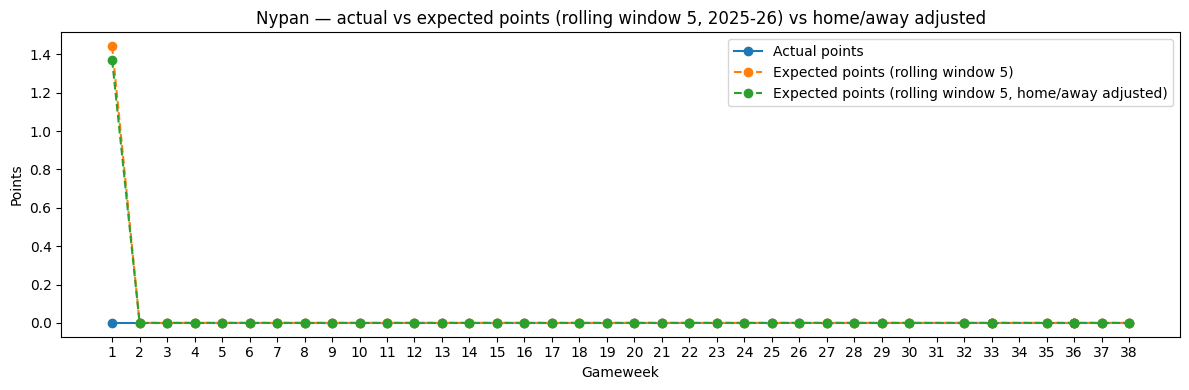

In [347]:
random_player = df.sample(1)
player_code = random_player["code"].values[0]
player_name = random_player["web_name"].values[0]

player_df = df[df["code"] == player_code].sort_values("round")

plt.figure(figsize=(12, 4))
plt.plot(player_df["round"], player_df["total_points"], marker="o", label="Actual points")
plt.plot(player_df["round"], player_df["xP_rw_5"], marker="o", linestyle="--", label="Expected points (rolling window 5)")
plt.plot(player_df["round"], player_df["xP_rw_5_home_away_adjusted"], marker="o", linestyle="--", label="Expected points (rolling window 5, home/away adjusted)")
plt.xlabel("Gameweek")
plt.ylabel("Points")
plt.title(f"{player_name} — actual vs expected points (rolling window 5, 2025-26) vs home/away adjusted")
plt.legend()
plt.xticks(range(1, 39))
plt.tight_layout()
plt.show()

Model                         MAE   RMSE      R²
--------------------------------------------------
xP: window-1                1.142  2.560  -0.190
xP: window-5                1.044  2.108   0.193
xP: window-5 + H/A          1.042  2.104   0.196


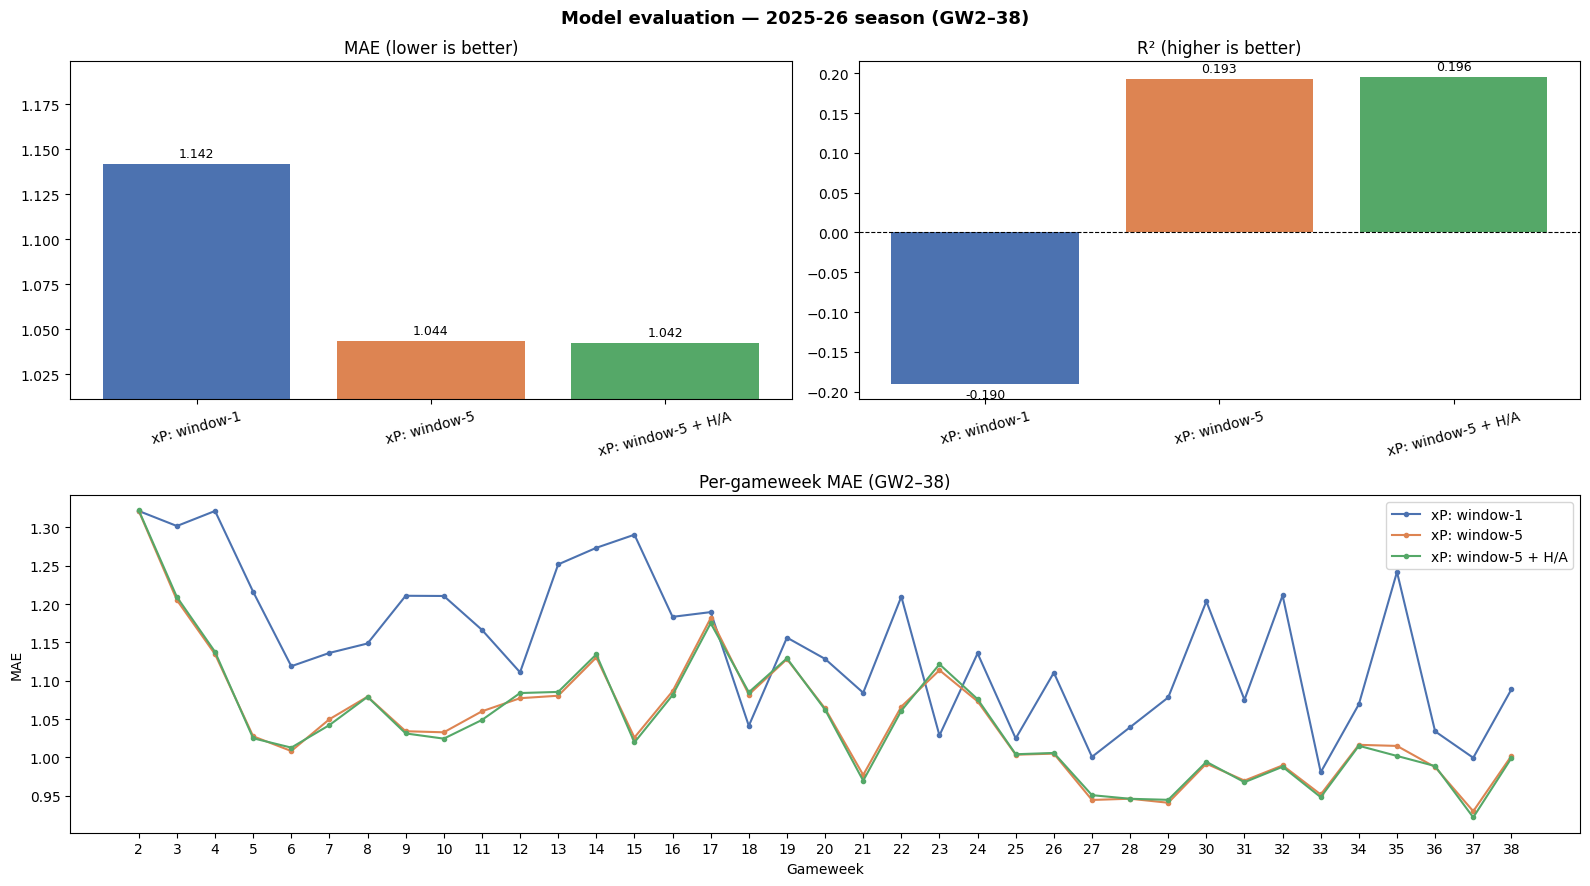

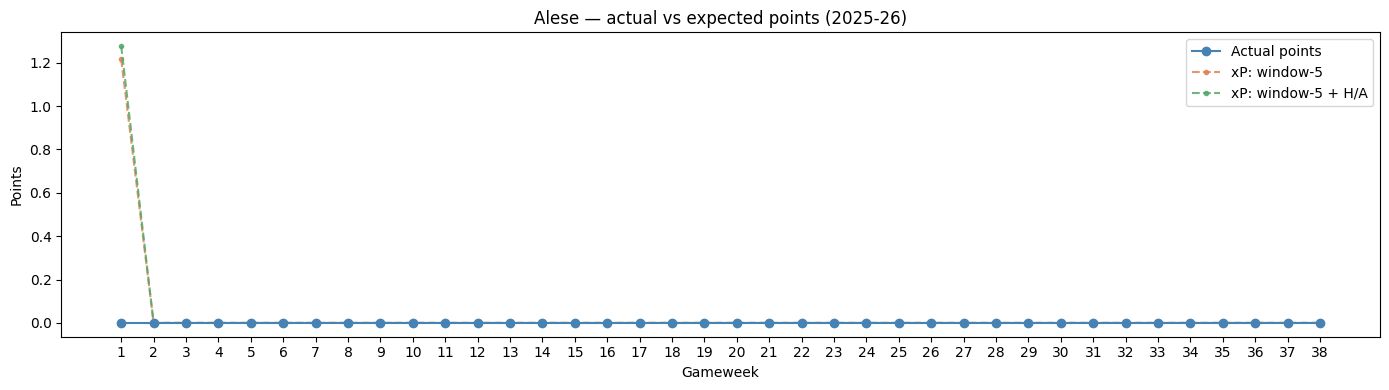

In [348]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "xP: window-1":          "xP_rw_1",
    "xP: window-5":          "xP_rw_5",
    "xP: window-5 + H/A":   "xP_rw_5_home_away_adjusted",
}

eval_df = df[df["round"] > 1].dropna(subset=list(models.values()))

# --- Summary table ---
summary = {}
print(f"{'Model':<26} {'MAE':>6} {'RMSE':>6} {'R²':>7}")
print("-" * 50)
for label, col in models.items():
    mae  = mean_absolute_error(eval_df["total_points"], eval_df[col])
    rmse = mean_squared_error(eval_df["total_points"], eval_df[col]) ** 0.5
    r2   = r2_score(eval_df["total_points"], eval_df[col])
    summary[label] = {"MAE": mae, "RMSE": rmse, "R2": r2}
    print(f"{label:<26} {mae:>6.3f} {rmse:>6.3f} {r2:>7.3f}")

# --- Plots ---
fig = plt.figure(figsize=(16, 9))
gs  = gridspec.GridSpec(2, 2, figure=fig)

colors = ["#4C72B0", "#DD8452", "#55A868"]

# Top-left: MAE bar
ax1 = fig.add_subplot(gs[0, 0])
bars = ax1.bar(list(models.keys()), [summary[l]["MAE"] for l in models], color=colors)
ax1.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
ax1.set_ylim(min(summary[l]["MAE"] for l in models) * 0.97,
             max(summary[l]["MAE"] for l in models) * 1.05)
ax1.set_title("MAE (lower is better)")
ax1.tick_params(axis="x", rotation=15)

# Top-right: R² bar
ax2 = fig.add_subplot(gs[0, 1])
bars = ax2.bar(list(models.keys()), [summary[l]["R2"] for l in models], color=colors)
ax2.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
ax2.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax2.set_title("R² (higher is better)")
ax2.tick_params(axis="x", rotation=15)

# Bottom: per-GW MAE
ax3 = fig.add_subplot(gs[1, :])
for (label, col), color in zip(models.items(), colors):
    gw_mae = eval_df.groupby("round").apply(
        lambda g: mean_absolute_error(g["total_points"], g[col])
    )
    ax3.plot(gw_mae.index, gw_mae.values, marker="o", markersize=3, label=label, color=color)
ax3.set_xlabel("Gameweek")
ax3.set_ylabel("MAE")
ax3.set_title("Per-gameweek MAE (GW2–38)")
ax3.set_xticks(range(2, 39))
ax3.legend()

plt.suptitle("Model evaluation — 2025-26 season (GW2–38)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# --- Favourite plot: random player, all three xP lines ---
player_row  = df[df["round"] == 19].sample(1)  # mid-season so all models have data
player_code = player_row["code"].values[0]
player_name = player_row["web_name"].values[0]
player_df   = df[df["code"] == player_code].sort_values("round")

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(player_df["round"], player_df["total_points"], marker="o", color="steelblue", label="Actual points", zorder=3)
for (label, col), color in zip(list(models.items())[1:], colors[1:]):  # skip window-1
    ax.plot(player_df["round"], player_df[col], marker="o", markersize=3,
            linestyle="--", color=color, label=label, alpha=0.85)
ax.set_xlabel("Gameweek")
ax.set_ylabel("Points")
ax.set_title(f"{player_name} — actual vs expected points (2025-26)")
ax.legend()
ax.set_xticks(range(1, 39))
plt.tight_layout()
plt.show()


xP window -5 + H/A better: 10, worse: 3, similar: 24 (difference < 0.005)


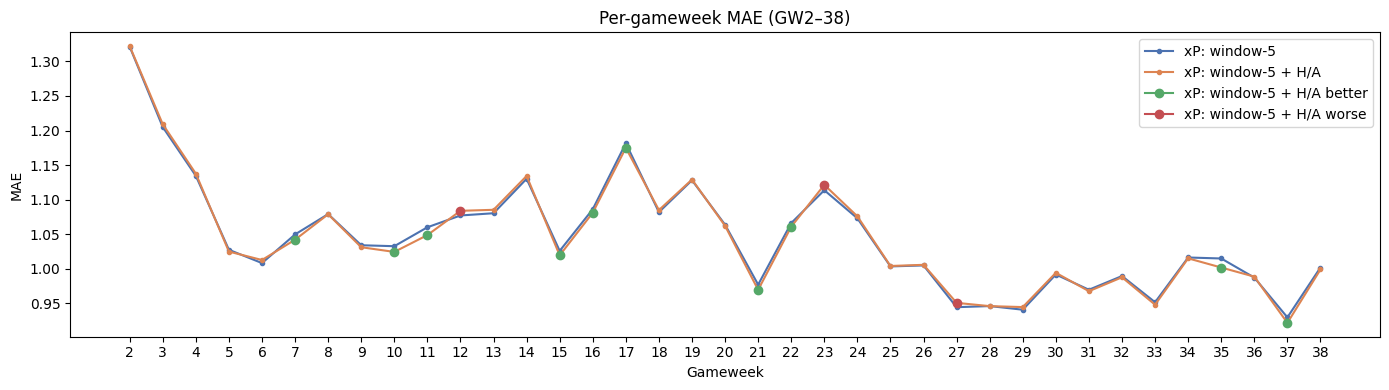

In [349]:
# per gameweek MAE - how many times was the xP window -5 + H/A better than the xP window -5? (lower MAE is better) (ignore for differences less than 0.01)
difference_threshold = 0.005
eval_df = df[df["round"] > 1].dropna(subset=["xP_rw_5", "xP_rw_5_home_away_adjusted"])
gw_mae = (
    eval_df.groupby("round")
    .apply(lambda g: {
        "xP_rw_5": mean_absolute_error(g["total_points"], g["xP_rw_5"]),
        "xP_rw_5_home_away_adjusted": mean_absolute_error(g["total_points"], g["xP_rw_5_home_away_adjusted"]),
    })
    .apply(lambda d: pd.Series(d))
)

# count how many times xP window -5 + H/A was better than xP window -5 (lower MAE is better) (ignore for differences less than 0.01)
better_count = (gw_mae["xP_rw_5_home_away_adjusted"] < gw_mae["xP_rw_5"] - difference_threshold).sum()
worse_count = (gw_mae["xP_rw_5_home_away_adjusted"] > gw_mae["xP_rw_5"] + difference_threshold).sum()
print(f"xP window -5 + H/A better: {better_count}, worse: {worse_count}, similar: {len(gw_mae) - better_count - worse_count} (difference < {difference_threshold})")


# plot the per gameweek MAE for xP window -5 and xP window -5 + H/A
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(gw_mae.index, gw_mae["xP_rw_5"], marker="o", markersize=3, label="xP: window-5", color="#4C72B0")
ax.plot(gw_mae.index, gw_mae["xP_rw_5_home_away_adjusted"], marker="o", markersize=3, label="xP: window-5 + H/A", color="#DD8452")
ax.set_xlabel("Gameweek")
ax.set_ylabel("MAE")
ax.set_title("Per-gameweek MAE (GW2–38)")
ax.set_xticks(range(2, 39))
for gw in gw_mae.index:
    if abs(gw_mae.loc[gw, "xP_rw_5_home_away_adjusted"] - gw_mae.loc[gw, "xP_rw_5"]) >= difference_threshold:
        if gw_mae.loc[gw, "xP_rw_5_home_away_adjusted"] < gw_mae.loc[gw, "xP_rw_5"]:
            ax.plot(gw, gw_mae.loc[gw, "xP_rw_5_home_away_adjusted"], marker="o", color="#55A868", markersize=6)
        else:
            ax.plot(gw, gw_mae.loc[gw, "xP_rw_5_home_away_adjusted"], marker="o", color="#C44E52", markersize=6)
# add to legend
ax.plot([], [], marker="o", color="#55A868", markersize=6, label="xP: window-5 + H/A better")
ax.plot([], [], marker="o", color="#C44E52", markersize=6, label="xP: window-5 + H/A worse")
ax.legend()
plt.tight_layout()
plt.show()



## Iteration 2
Adjust Lookback 5 to use EWMA

In [350]:
SPAN = 5

wide = fpl_full_2025_26.pivot_table(index="round", columns="code", values="total_points")
rolled_ewma = wide.shift(1).ewm(span=SPAN, min_periods=1).mean()

exp_ewma = (
    rolled_ewma.stack()
    .reset_index()
    .rename(columns={0: "_exp_ewma_tmp"})
)

# Merge into existing df (preserves xP_rw_5 and all other columns).
df = df.merge(exp_ewma, on=["round", "code"], how="left")

gw1 = df["round"] == 1
df.loc[gw1, "_exp_ewma_tmp"] = df.loc[gw1, "code"].map(code_to_prior)

pos_avg_ewma = df.groupby(["round", "position"])["_exp_ewma_tmp"].transform("mean")
df["xP_ewma_5"] = df["_exp_ewma_tmp"].fillna(pos_avg_ewma)
df.drop(columns=["_exp_ewma_tmp"], inplace=True)

print(f"Coverage: {df['xP_ewma_5'].notna().mean():.1%}")
df[["round", "web_name", "position", "total_points", "xP_rw_5", "xP_ewma_5"]].head(20)


Coverage: 100.0%


,round,web_name,position,total_points,xP_rw_5,xP_ewma_5
0,1,Raya,GKP,10,3.736842,3.736842
1,1,Arrizabalaga,GKP,0,2.789474,2.789474
2,1,Hein,GKP,0,0.000000,0.000000
3,1,Setford,GKP,0,0.000000,0.000000
4,1,Gabriel,DEF,6,3.078947,3.078947
5,1,Saliba,DEF,9,3.421053,3.421053
6,1,Calafiori,DEF,13,1.026316,1.026316
7,1,J.Timber,DEF,0,3.000000,3.000000
8,1,Kiwior,DEF,0,1.131579,1.131579
9,1,Lewis-Skelly,DEF,0,0.973684,0.973684


In [351]:
# verify computation
# test with web_name == 'Raya'
# output all instances with web_name 'Raya'
name_to_check = 'Raya'
df_to_check = df[df['web_name'] == name_to_check]
cols_to_keep = ['round', 'total_points', 'xP_rw_5', 'xP_ewma_5', 'web_name'] 
print(df_to_check[cols_to_keep])


       round  total_points    xP_rw_5  xP_ewma_5 web_name
0          1            10   3.736842   3.736842     Raya
690        2             6  10.000000  10.000000     Raya
1395       3             2   8.000000   7.600000     Raya
2107       4             6   6.000000   4.947368     Raya
2847       5             2   6.000000   5.384615     Raya
3588       6             2   5.200000   4.085308     Raya
4330       7             6   3.600000   3.323308     Raya
5073       8             6   3.600000   4.271005     Raya
5818       9             6   4.400000   4.870738     Raya
6564      10             6   4.400000   5.257211     Raya
7311      11             1   5.200000   5.509177     Raya
8063      12             2   5.000000   3.988538     Raya
8818      13             3   4.200000   3.320543     Raya
9573      14             6   3.600000   3.213144     Raya
10331     15             2   3.600000   4.145289     Raya
11090     16             2   2.800000   3.428556     Raya
11850     17  

In [352]:
# quickly - apply home/away adjustment to xP_ewma_5 to create xP_ewma_5_home_away_adjusted
home_multiplier = 1.05
away_multiplier = 0.95
df['xP_ewma_5_home_away_adjusted'] = df['xP_ewma_5'] * df['was_home'].map({True: home_multiplier, False: away_multiplier})

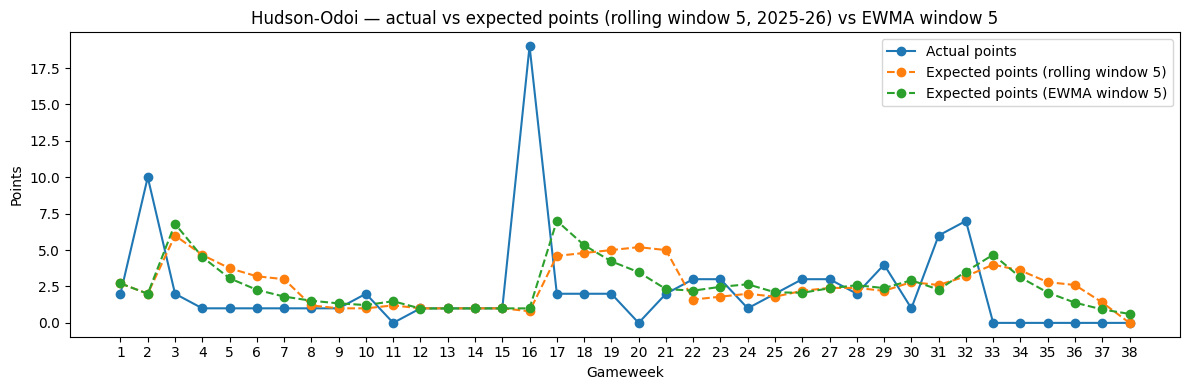

In [353]:
random_player = df.sample(1)
player_code = random_player["code"].values[0]
player_name = random_player["web_name"].values[0]

player_df = df[df["code"] == player_code].sort_values("round")

plt.figure(figsize=(12, 4))
plt.plot(player_df["round"], player_df["total_points"], marker="o", label="Actual points")
plt.plot(player_df["round"], player_df["xP_rw_5"], marker="o", linestyle="--", label="Expected points (rolling window 5)")
plt.plot(player_df["round"], player_df["xP_ewma_5"], marker="o", linestyle="--", label="Expected points (EWMA window 5)")
plt.xlabel("Gameweek")
plt.ylabel("Points")
plt.title(f"{player_name} — actual vs expected points (rolling window 5, 2025-26) vs EWMA window 5")
plt.legend()
plt.xticks(range(1, 39))
plt.tight_layout()
plt.show()

Model                         MAE   RMSE      R²
--------------------------------------------------
xP: window-1                1.142  2.560  -0.190
xP: window-5                1.044  2.108   0.193
xP: window-5 + H/A          1.042  2.104   0.196
xP: EWMA-5                  1.022  2.081   0.214
xP: EWMA-5 + H/A            1.021  2.077   0.217


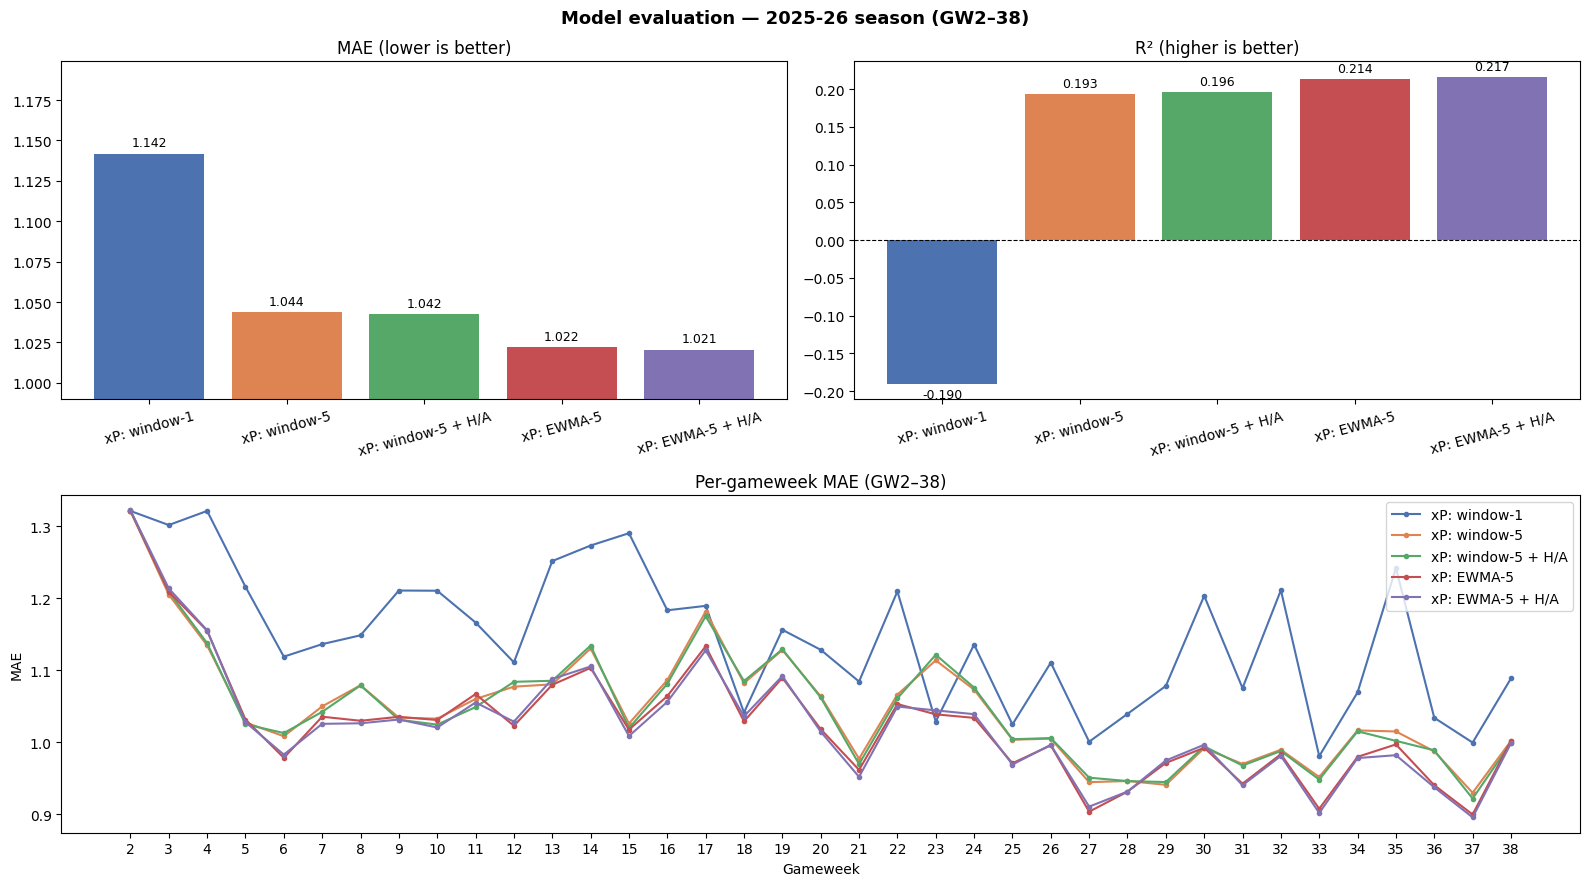

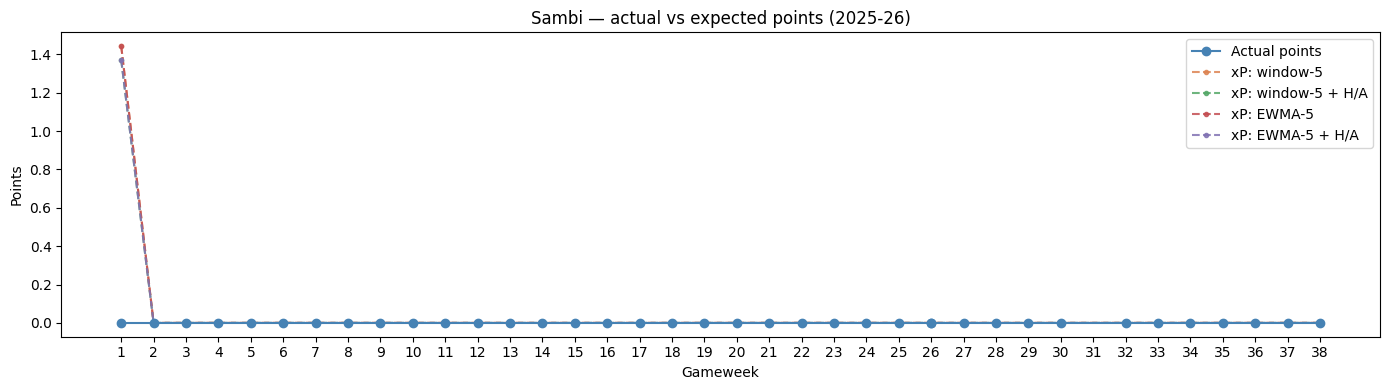

In [354]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "xP: window-1":          "xP_rw_1",
    "xP: window-5":          "xP_rw_5",
    "xP: window-5 + H/A":   "xP_rw_5_home_away_adjusted",
    "xP: EWMA-5":             "xP_ewma_5",
    "xP: EWMA-5 + H/A":         "xP_ewma_5_home_away_adjusted"
}

eval_df = df[df["round"] > 1].dropna(subset=list(models.values()))

# --- Summary table ---
summary = {}
print(f"{'Model':<26} {'MAE':>6} {'RMSE':>6} {'R²':>7}")
print("-" * 50)
for label, col in models.items():
    mae  = mean_absolute_error(eval_df["total_points"], eval_df[col])
    rmse = mean_squared_error(eval_df["total_points"], eval_df[col]) ** 0.5
    r2   = r2_score(eval_df["total_points"], eval_df[col])
    summary[label] = {"MAE": mae, "RMSE": rmse, "R2": r2}
    print(f"{label:<26} {mae:>6.3f} {rmse:>6.3f} {r2:>7.3f}")

# --- Plots ---
fig = plt.figure(figsize=(16, 9))
gs  = gridspec.GridSpec(2, 2, figure=fig)

colors = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"]

# Top-left: MAE bar
ax1 = fig.add_subplot(gs[0, 0])
bars = ax1.bar(list(models.keys()), [summary[l]["MAE"] for l in models], color=colors)
ax1.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
ax1.set_ylim(min(summary[l]["MAE"] for l in models) * 0.97,
             max(summary[l]["MAE"] for l in models) * 1.05)
ax1.set_title("MAE (lower is better)")
ax1.tick_params(axis="x", rotation=15)

# Top-right: R² bar
ax2 = fig.add_subplot(gs[0, 1])
bars = ax2.bar(list(models.keys()), [summary[l]["R2"] for l in models], color=colors)
ax2.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
ax2.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax2.set_title("R² (higher is better)")
ax2.tick_params(axis="x", rotation=15)

# Bottom: per-GW MAE
ax3 = fig.add_subplot(gs[1, :])
for (label, col), color in zip(models.items(), colors):
    gw_mae = eval_df.groupby("round").apply(
        lambda g: mean_absolute_error(g["total_points"], g[col])
    )
    ax3.plot(gw_mae.index, gw_mae.values, marker="o", markersize=3, label=label, color=color)
ax3.set_xlabel("Gameweek")
ax3.set_ylabel("MAE")
ax3.set_title("Per-gameweek MAE (GW2–38)")
ax3.set_xticks(range(2, 39))
ax3.legend()

plt.suptitle("Model evaluation — 2025-26 season (GW2–38)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# --- Favourite plot: random player, all three xP lines ---
player_row  = df[df["round"] == 19].sample(1)  # mid-season so all models have data
player_code = player_row["code"].values[0]
player_name = player_row["web_name"].values[0]
player_df   = df[df["code"] == player_code].sort_values("round")

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(player_df["round"], player_df["total_points"], marker="o", color="steelblue", label="Actual points", zorder=3)
for (label, col), color in zip(list(models.items())[1:], colors[1:]):  # skip window-1
    ax.plot(player_df["round"], player_df[col], marker="o", markersize=3,
            linestyle="--", color=color, label=label, alpha=0.85)
ax.set_xlabel("Gameweek")
ax.set_ylabel("Points")
ax.set_title(f"{player_name} — actual vs expected points (2025-26)")
ax.legend()
ax.set_xticks(range(1, 39))
plt.tight_layout()
plt.show()


Random player: Konaté (code: 204716) in GW 38
Actual points: 1
Predicted points: 1.737
Difference: -0.737
Fractional error: -73.675%


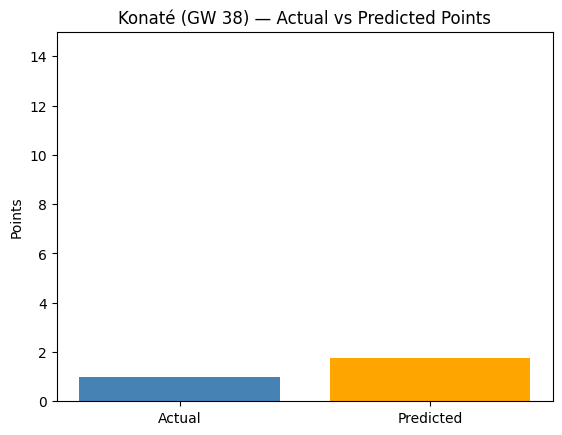

In [355]:
# for fun - pick a random player in a random gameweek, show their predicted and actual points using the ewma h/a adjusted model, and show the difference
# change df so it's only players whose total points were greater than 5
df_to_use = df[df['total_points'] > 0]

random_row = df_to_use.sample(1)
player_name = random_row["web_name"].values[0]
player_code = random_row["code"].values[0]
player_round = random_row["round"].values[0]
actual_points = random_row["total_points"].values[0]
predicted_points = random_row["xP_ewma_5_home_away_adjusted"].values[0]
difference = actual_points - predicted_points

# make print statement more readable
print(f"Random player: {player_name} (code: {player_code}) in GW {player_round}")
print(f"Actual points: {actual_points}")
print(f"Predicted points: {predicted_points:.3f}")
print(f"Difference: {difference:.3f}")
# output fractional error:
if actual_points != 0:
    fractional_error = difference / actual_points
else:
    fractional_error = 0
print(f"Fractional error: {fractional_error:.3%}")
# visualise the above with a bar chart
import matplotlib.pyplot as plt
plt.bar(["Actual", "Predicted"], [actual_points, predicted_points], color=["steelblue", "orange"])
plt.title(f"{player_name} (GW {player_round}) — Actual vs Predicted Points")
# set constant y axis height from 0 to 15
plt.ylim(0, 15)
plt.ylabel("Points")
plt.show()

In [356]:
# output the top 100 hauls in the 2025-26 season, sorted by total points, with their predicted points and difference
top_100_hauls = df.sort_values("total_points", ascending=False).head(100)
top_100_hauls = top_100_hauls[["round", "web_name", "team_name", "position", "total_points", "xP_ewma_5_home_away_adjusted"]]
top_100_hauls["difference"] = top_100_hauls["total_points"] - top_100_hauls["xP_ewma_5_home_away_adjusted"]
top_100_hauls = top_100_hauls.sort_values("total_points", ascending=False)
print(top_100_hauls.head(20))

       round      web_name      team_name position  total_points  xP_ewma_5_home_away_adjusted  difference
697        2      J.Timber        Arsenal      DEF            24                      0.000000   24.000000
6392       9    Van de Ven          Spurs      DEF            23                      2.073878   20.926122
24434     32    Mavropanos       West Ham      DEF            21                      5.116299   15.883701
11956     17  Lewis-Potter      Brentford      DEF            21                      2.455228   18.544772
18407     25        Palmer        Chelsea      MID            20                      2.648022   17.351978
25376     33   Gibbs-White  Nott'm Forest      MID            20                      4.963663   15.036337
12739     18        Schade      Brentford      MID            20                      2.070641   17.929359
8328      12           Eze        Arsenal      MID            20                      4.256104   15.743896
11605     16   Hudson-Odoi  Nott'm Fo

## Iteration 3
Adjust forward expected points based on their opponents' defensive strength (using expected goals conceded)

In [357]:
# for the second gameweek, calculate the opponent defensive strength using the expected_goals_conceded from the previous gameweek 
team_expected_goals_conceded = df.groupby(['round', 'team_name'])['expected_goals_conceded'].max().reset_index()
team_expected_goals_conceded = team_expected_goals_conceded.rename(columns={'expected_goals_conceded': 'team_expected_goals_conceded'})
flag = 1
if flag == 1:
    df = df.merge(team_expected_goals_conceded, on=['round', 'team_name'], how='left')

team_goals_conceded = df.groupby(['round', 'team_name'])['goals_conceded'].max().reset_index()
team_goals_conceded = team_goals_conceded.rename(columns={'goals_conceded': 'team_goals_conceded'})

flag = 1
if flag == 1:
    df = df.merge(team_goals_conceded, on=['round', 'team_name'], how='left')

pd.set_option('display.max_columns', None)
pd.set_option('display.expand_frame_repr', False)
# output random team and round 2
random_team = df.sample(1)
team_name = random_team["team_name"].values[0]
print(f"Random team: {team_name}")
random_team_gw2 = df[(df['team_name'] == team_name) & (df['round'] == 5)]
random_team_gw2 = random_team_gw2[['round','team_name', 'web_name', 'position', 'total_points', 'xP_ewma_5_home_away_adjusted', 'expected_goals_conceded', 'team_expected_goals_conceded']]
print(random_team_gw2)
# First, we need to calculate every team's expected goals conceded for every gameweek. This can be done by:
# for each round, group by team_name, and then take the maximum expected_goals_conceded for that team in that round. This will give us the expected goals conceded for each team in each gameweek. We then need to save this in a new column called 'team_expected_goals_conceded' in the df. This will be used to calculate the opponent defensive strength for each player in the next gameweek.

# now that we have team expected goals conceded, we need to create x_team_goals_conceded_ewma_N, which is the ewma with Lookback = N (to be decided, but we'll do 5 for now), so we need to get the previous five games of team_expected_goals_conceded, and do the ewma thing, and produce this column. The next step is to calculate what sort of boost to give the forwards depending on the opponent team's defensive strength, add home/away adjustments to the defensive strengths (or would that be doubling the home/away adjustments if there's already the H/A adjustment on the xP_ewma_5_home_away_adjusted?). Then we can optimise the lookback for the expected expected goals conceded. 


SPAN = 5

wide = df.pivot_table(index="round", columns="code", values="team_expected_goals_conceded")
rolled_ewma = wide.shift(1).ewm(span=SPAN, min_periods=1).mean()

exp_ewma = (
    rolled_ewma.stack()
    .reset_index()
    .rename(columns={0: "_exp_ewma_tmp"})
)

# Merge into existing df (preserves xP_rw_5 and all other columns).
df = df.merge(exp_ewma, on=["round", "code"], how="left")

gw1 = df["round"] == 1
df.loc[gw1, "_exp_ewma_tmp"] = df.loc[gw1, "code"].map(code_to_prior)

pos_avg_ewma = df.groupby(["round", "position"])["_exp_ewma_tmp"].transform("mean")
this_value = 0
df["x_team_goals_conceded_ewma_N"] = df["_exp_ewma_tmp"].fillna(this_value)
df.drop(columns=["_exp_ewma_tmp"], inplace=True)

print(f"Coverage: {df['x_team_goals_conceded_ewma_N'].notna().mean():.1%}")
df[["round", "web_name", "position", "total_points", "xP_rw_5", "x_team_goals_conceded_ewma_N"]].head(20)

SPAN = 5

wide = df.pivot_table(index="round", columns="code", values="team_goals_conceded")
rolled_ewma = wide.shift(1).ewm(span=SPAN, min_periods=1).mean()

exp_ewma = (
    rolled_ewma.stack()
    .reset_index()
    .rename(columns={0: "_exp_ewma_tmp"})
)

# Merge into existing df (preserves xP_rw_5 and all other columns).
df = df.merge(exp_ewma, on=["round", "code"], how="left")

gw1 = df["round"] == 1
df.loc[gw1, "_exp_ewma_tmp"] = df.loc[gw1, "code"].map(code_to_prior)

pos_avg_ewma = df.groupby(["round", "position"])["_exp_ewma_tmp"].transform("mean")
this_value = 0
df["gus_x_team_goals_conceded_ewma_N"] = df["_exp_ewma_tmp"].fillna(this_value)
df.drop(columns=["_exp_ewma_tmp"], inplace=True)

print(f"Coverage: {df['gus_x_team_goals_conceded_ewma_N'].notna().mean():.1%}")
df[["round", "web_name", "position", "total_points", "xP_rw_5", "gus_x_team_goals_conceded_ewma_N"]].head(20)


Random team: Spurs
      round team_name     web_name position  total_points  xP_ewma_5_home_away_adjusted  expected_goals_conceded  team_expected_goals_conceded
3411      5     Spurs      Vicario      GKP             1                      6.576923                     1.32                          1.32
3412      5     Spurs       Austin      GKP             0                      0.000000                     0.00                          1.32
3413      5     Spurs       Kinsky      GKP             0                      0.000000                     0.00                          1.32
3414      5     Spurs  Pedro Porro      DEF             1                      4.998462                     1.32                          1.32
3415      5     Spurs       Romero      DEF             2                      7.190769                     1.32                          1.32
3416      5     Spurs        Danso      DEF             0                      0.570000                     0.00           

,round,web_name,position,total_points,xP_rw_5,gus_x_team_goals_conceded_ewma_N
0,1,Raya,GKP,10,3.736842,3.736842
1,1,Arrizabalaga,GKP,0,2.789474,2.789474
2,1,Hein,GKP,0,0.000000,0.000000
3,1,Setford,GKP,0,0.000000,0.000000
4,1,Gabriel,DEF,6,3.078947,3.078947
5,1,Saliba,DEF,9,3.421053,3.421053
6,1,Calafiori,DEF,13,1.026316,1.026316
7,1,J.Timber,DEF,0,3.000000,3.000000
8,1,Kiwior,DEF,0,1.131579,1.131579
9,1,Lewis-Skelly,DEF,0,0.973684,0.973684


In [358]:
# check to see if worked:
pd.set_option('display.max_columns', None)
pd.set_option('display.expand_frame_repr', False)
# output random team and round 2
random_team = df.sample(1)
team_name = random_team["team_name"].values[0]
print(f"Random team: {team_name}")
for i in range(5):
    random_team_gw2 = df[(df['team_name'] == team_name) & (df['round'] == i+1)]
    random_team_gw2 = random_team_gw2[['round','team_name', 'web_name', 'position', 'total_points', 'team_expected_goals_conceded', 'x_team_goals_conceded_ewma_N']]
    print(random_team_gw2)


Random team: Man Utd
     round team_name     web_name position  total_points  team_expected_goals_conceded  x_team_goals_conceded_ewma_N
118      1   Man Utd       Mbeumo      MID             2                          1.31                      6.210526
430      1   Man Utd     Bayindir      GKP             2                          1.31                      0.210526
431      1   Man Utd        Onana      GKP             0                          1.31                      3.157895
432      1   Man Utd     Harrison      GKP             0                          1.31                      0.000000
433      1   Man Utd       Heaton      GKP             0                          1.31                      0.000000
434      1   Man Utd          Mee      GKP             0                          1.31                      0.000000
435      1   Man Utd      De Ligt      DEF             4                          1.31                      1.789474
436      1   Man Utd     Martinez      DEF 

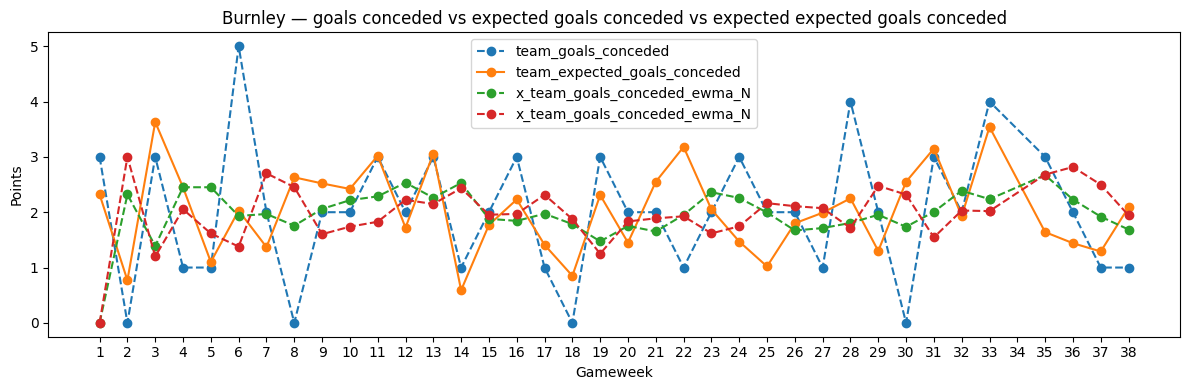

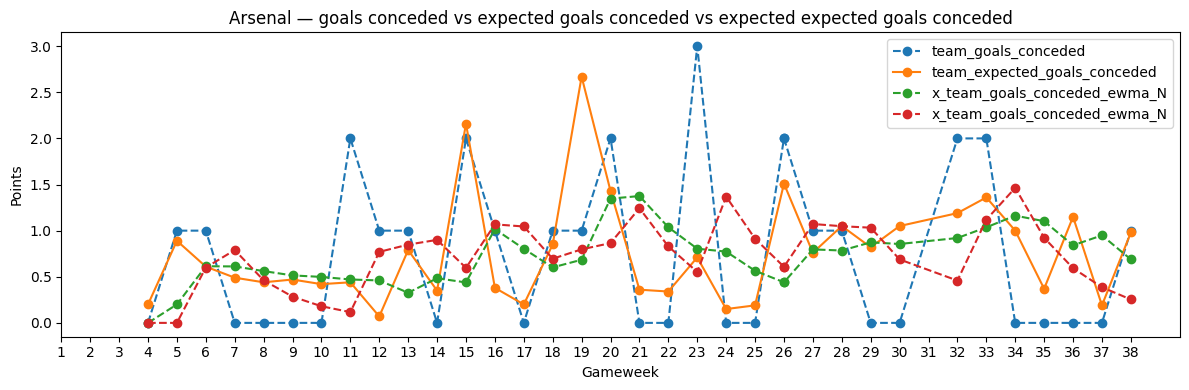

In [359]:
team_to_investigate = ['Burnley', 'Arsenal']
range_of_teams = len(team_to_investigate)
for i in range(range_of_teams):
    random_player = df[df['team_name'] == team_to_investigate[i]].sample(1)
    player_code = random_player["code"].values[0]
    player_name = random_player["web_name"].values[0]

    player_df = df[df["code"] == player_code].sort_values("round")

    plt.figure(figsize=(12, 4))
    plt.plot(player_df["round"], player_df["team_goals_conceded"], marker="o", linestyle="--", label="team_goals_conceded")
    plt.plot(player_df["round"], player_df["team_expected_goals_conceded"], marker="o", label="team_expected_goals_conceded")
    plt.plot(player_df["round"], player_df["x_team_goals_conceded_ewma_N"], marker="o", linestyle="--", label="x_team_goals_conceded_ewma_N")
    plt.plot(player_df["round"], player_df["gus_x_team_goals_conceded_ewma_N"], marker="o", linestyle="--", label="x_team_goals_conceded_ewma_N")
    plt.xlabel("Gameweek")
    plt.ylabel("Points")
    plt.title(f"{team_to_investigate[i]} — goals conceded vs expected goals conceded vs expected expected goals conceded")
    plt.legend()
    plt.xticks(range(1, 39))
    plt.tight_layout()
    plt.show()

In [360]:
import numpy as np

# --- Step 1: team-level xGC per round ---
team_xgc = (
    df.groupby(["round", "team_name"])["expected_goals_conceded"]
    .max()
    .reset_index()
    .rename(columns={"expected_goals_conceded": "team_xgc"})
)

# --- Step 2: EWMA-5 of each team's xGC, shifted to avoid leakage ---
SPAN = 5
team_wide = team_xgc.pivot(index="round", columns="team_name", values="team_xgc")
team_xgc_ewma = (
    team_wide.shift(1).ewm(span=SPAN, min_periods=1).mean()
    .stack()
    .reset_index()
    .rename(columns={0: "opp_xgc_ewma_5"})
)
league_avg_xgc = team_xgc["team_xgc"].mean()
gw1_mask = team_xgc_ewma["round"] == 1
team_xgc_ewma.loc[gw1_mask, "opp_xgc_ewma_5"] = league_avg_xgc

# --- Step 3: join on opponent team ---
if "opp_xgc_ewma_5" in df.columns:
    df = df.drop(columns=["opp_xgc_ewma_5"])
df = df.merge(
    team_xgc_ewma.rename(columns={"team_name": "opponent_team_name"}),
    on=["round", "opponent_team_name"],
    how="left",
)
df["opp_strength"] = df["opp_xgc_ewma_5"] / league_avg_xgc

# --- Step 4: empirical alpha from FWD/MID data (no grid search — avoids leakage) ---
fwd_mid = df[(df["position"].isin(["FWD", "MID"])) & (df["round"] > 1)]
alpha = (
    np.cov(fwd_mid["opp_strength"], fwd_mid["total_points"])[0, 1]
    / np.var(fwd_mid["opp_strength"])
)
print(f"Empirical alpha: {alpha:.4f}")
print(f"Boost range before dampening: {df['opp_strength'].min():.3f} – {df['opp_strength'].max():.3f}")

# --- Step 5: dampened boost applied to FWD/MID only ---
df["opp_boost"] = 1 + alpha * (df["opp_strength"] - 1)
print(f"Boost range after dampening:  {df['opp_boost'].min():.3f} – {df['opp_boost'].max():.3f}")

is_attacker = df["position"].isin(["FWD", "MID"])
df["xP_ewma_5_ha_opp"] = df["xP_ewma_5_home_away_adjusted"].copy()
df.loc[is_attacker, "xP_ewma_5_ha_opp"] = (
    df.loc[is_attacker, "xP_ewma_5_home_away_adjusted"]
    * df.loc[is_attacker, "opp_boost"]
)

# --- Step 6: metrics (GW2+) ---
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
df_to_check = df[df['position'].isin(['FWD', 'MID'])]
df_to_check = df_to_check[df_to_check['minutes'] > 1]
eval_df = df_to_check[df_to_check["round"] > 1].dropna(subset=["xP_ewma_5_home_away_adjusted", "xP_ewma_5_ha_opp"])

models = {
    "xP: EWMA-5 + H/A":        "xP_ewma_5_home_away_adjusted",
    "xP: EWMA-5 + H/A + Opp":  "xP_ewma_5_ha_opp",
}
print()
print(f"{'Model':<28} {'MAE':>6} {'RMSE':>6} {'R²':>7}")
print("-" * 52)
for label, col in models.items():
    mae  = mean_absolute_error(eval_df["total_points"], eval_df[col])
    rmse = mean_squared_error(eval_df["total_points"], eval_df[col]) ** 0.5
    r2   = r2_score(eval_df["total_points"], eval_df[col])
    print(f"{label:<28} {mae:>6.3f} {rmse:>6.3f} {r2:>7.3f}")


Empirical alpha: 0.0893
Boost range before dampening: 0.143 – 1.903
Boost range after dampening:  0.923 – 1.081

Model                           MAE   RMSE      R²
----------------------------------------------------
xP: EWMA-5 + H/A              2.080  3.086  -0.110
xP: EWMA-5 + H/A + Opp        2.077  3.083  -0.107


Best MAE at span=37: 1.0194  (span=5: 1.0198)


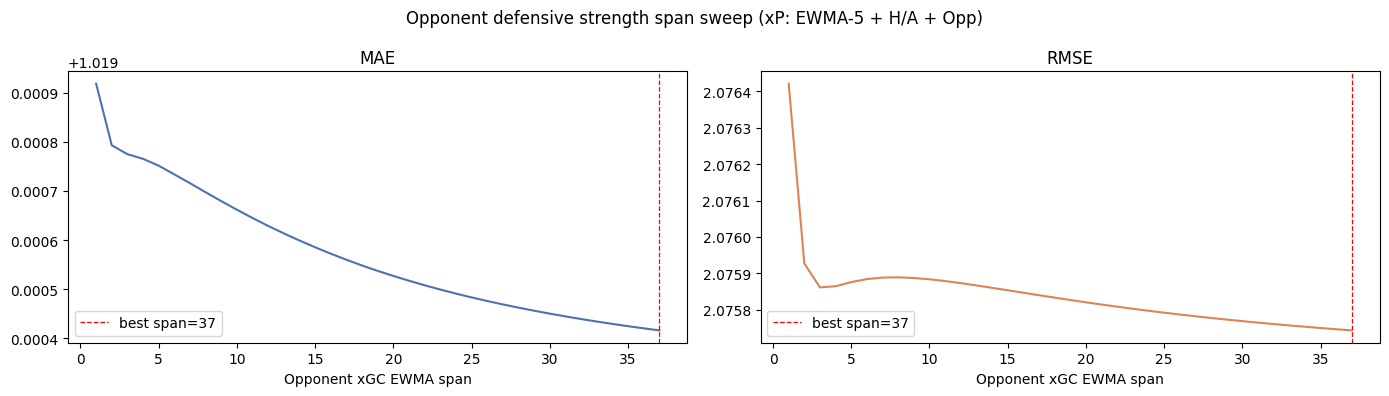

,MAE,RMSE
span,,
1,1.019918,2.076421
2,1.019793,2.075927
3,1.019775,2.075861
4,1.019765,2.075864
5,1.019751,2.075876
6,1.019734,2.075884
7,1.019716,2.075888
8,1.019697,2.075889
9,1.019679,2.075887


In [361]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

ALPHA = 0.0893  # empirical alpha from span=5 — fixed for sweep

team_xgc = (
    df.groupby(["round", "team_name"])["expected_goals_conceded"]
    .max().reset_index()
    .rename(columns={"expected_goals_conceded": "team_xgc"})
)
league_avg_xgc = team_xgc["team_xgc"].mean()
team_wide = team_xgc.pivot(index="round", columns="team_name", values="team_xgc")

base_cols = ["round", "code", "position", "opponent_team_name", "total_points", "xP_ewma_5_home_away_adjusted"]
base = df[base_cols].copy()

sweep_results = []
for span in range(1, 38):
    ewma = (
        team_wide.shift(1).ewm(span=span, min_periods=1).mean()
        .stack().reset_index()
        .rename(columns={0: "opp_xgc_ewma", "team_name": "opponent_team_name"})
    )
    ewma.loc[ewma["round"] == 1, "opp_xgc_ewma"] = league_avg_xgc

    tmp = base.merge(ewma, on=["round", "opponent_team_name"], how="left")
    tmp["opp_boost"] = 1 + ALPHA * (tmp["opp_xgc_ewma"] / league_avg_xgc - 1)

    is_att = tmp["position"].isin(["FWD", "MID"])
    tmp["xP_adj"] = tmp["xP_ewma_5_home_away_adjusted"].copy()
    tmp.loc[is_att, "xP_adj"] *= tmp.loc[is_att, "opp_boost"]

    ev = tmp[tmp["round"] > 1].dropna(subset=["xP_adj"])
    sweep_results.append({
        "span": span,
        "MAE":  mean_absolute_error(ev["total_points"], ev["xP_adj"]),
        "RMSE": mean_squared_error(ev["total_points"], ev["xP_adj"]) ** 0.5,
    })

sweep = pd.DataFrame(sweep_results).set_index("span")
best_mae = sweep["MAE"].idxmin()
print(f"Best MAE at span={best_mae}: {sweep.loc[best_mae, 'MAE']:.4f}  (span=5: {sweep.loc[5, 'MAE']:.4f})")

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharex=True)
for ax, metric, color in zip(axes, ["MAE", "RMSE"], ["#4C72B0", "#DD8452"]):
    ax.plot(sweep.index, sweep[metric], color=color)
    best = sweep[metric].idxmin()
    ax.axvline(best, color="red", linestyle="--", linewidth=0.9, label=f"best span={best}")
    ax.set_xlabel("Opponent xGC EWMA span")
    ax.set_title(metric)
    ax.legend()
plt.suptitle("Opponent defensive strength span sweep (xP: EWMA-5 + H/A + Opp)", fontsize=12)
plt.tight_layout()
plt.show()
sweep


In [362]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SPAN = 5

# ── Opponent DEFENSIVE strength (H/A split) → boosts FWD/MID ──────────────
# Home xGC: games where the team was at home (was_home == True)
home_def = (df[df["was_home"]].groupby(["round", "team_name"])["expected_goals_conceded"]
            .max().reset_index().rename(columns={"expected_goals_conceded": "xgc"}))
away_def = (df[~df["was_home"]].groupby(["round", "team_name"])["expected_goals_conceded"]
            .max().reset_index().rename(columns={"expected_goals_conceded": "xgc"}))

def team_ewma(df_team, val_col, out_col, league_avg, span=SPAN):
    wide = df_team.pivot(index="round", columns="team_name", values=val_col)
    result = (wide.shift(1).ewm(span=span, min_periods=1, ignore_na=True).mean()
              .stack().reset_index().rename(columns={0: out_col}))
    result.loc[result["round"] == 1, out_col] = league_avg
    return result

home_def_ewma = team_ewma(home_def, "xgc", "opp_xgc_home_ewma", home_def["xgc"].mean())
away_def_ewma = team_ewma(away_def, "xgc", "opp_xgc_away_ewma", away_def["xgc"].mean())

# ── Opponent OFFENSIVE strength (H/A split) → adjusts DEF/GK ─────────────
# Sum expected_goals per team per round to get team xG
home_off = (df[df["was_home"]].groupby(["round", "team_name"])["expected_goals"]
            .sum().reset_index().rename(columns={"expected_goals": "xg"}))
away_off = (df[~df["was_home"]].groupby(["round", "team_name"])["expected_goals"]
            .sum().reset_index().rename(columns={"expected_goals": "xg"}))

home_off_ewma = team_ewma(home_off, "xg", "opp_xg_home_ewma", home_off["xg"].mean())
away_off_ewma = team_ewma(away_off, "xg", "opp_xg_away_ewma", away_off["xg"].mean())

# ── Merge all four onto df via opponent_team_name ─────────────────────────
for col in ["opp_xgc_home_ewma", "opp_xgc_away_ewma", "opp_xg_home_ewma", "opp_xg_away_ewma"]:
    if col in df.columns:
        df = df.drop(columns=[col])

for ewma_df in [home_def_ewma, away_def_ewma, home_off_ewma, away_off_ewma]:
    df = df.merge(
        ewma_df.rename(columns={"team_name": "opponent_team_name"}),
        on=["round", "opponent_team_name"], how="left"
    )

# Select the right split: player at home → opponent is away, and vice versa
df["opp_def_ewma"] = df["opp_xgc_away_ewma"].where(df["was_home"], df["opp_xgc_home_ewma"])
df["opp_off_ewma"] = df["opp_xg_away_ewma"].where(df["was_home"], df["opp_xg_home_ewma"])

# ── Empirical alphas ───────────────────────────────────────────────────────
eval_gw2 = df[df["round"] > 1]

fwd_mid = eval_gw2[eval_gw2["position"].isin(["FWD", "MID"])].dropna(subset=["opp_def_ewma"])
league_avg_def = df.groupby(["round", "team_name"])["expected_goals_conceded"].max().mean()
fwd_mid_str = fwd_mid["opp_def_ewma"] / league_avg_def
alpha_att = np.cov(fwd_mid_str, fwd_mid["total_points"])[0,1] / np.var(fwd_mid_str)

def_gk = eval_gw2[eval_gw2["position"].isin(["DEF", "GK"])].dropna(subset=["opp_off_ewma"])
league_avg_off = home_off["xg"].mean()
def_gk_str = def_gk["opp_off_ewma"] / league_avg_off
alpha_def = np.cov(def_gk_str, def_gk["total_points"])[0,1] / np.var(def_gk_str)

print(f"Alpha (FWD/MID vs opp defensive weakness): {alpha_att:.4f}")
print(f"Alpha (DEF/GK  vs opp offensive threat):   {alpha_def:.4f}")

# ── Apply boosts ───────────────────────────────────────────────────────────
df["xP_ewma_5_ha_opp_v2"] = df["xP_ewma_5_home_away_adjusted"].copy()

is_att = df["position"].isin(["FWD", "MID"])
att_boost = 1 + alpha_att * (df.loc[is_att, "opp_def_ewma"] / league_avg_def - 1)
df.loc[is_att, "xP_ewma_5_ha_opp_v2"] *= att_boost

is_def = df["position"].isin(["DEF", "GK"])
def_boost = 1 + alpha_def * (df.loc[is_def, "opp_off_ewma"] / league_avg_off - 1)
df.loc[is_def, "xP_ewma_5_ha_opp_v2"] *= def_boost

# ── Metrics ────────────────────────────────────────────────────────────────
eval_df = df[df["round"] > 1].dropna(subset=["xP_ewma_5_ha_opp", "xP_ewma_5_ha_opp_v2"])
models = {
    "xP: EWMA-5 + H/A":             "xP_ewma_5_home_away_adjusted",
    "xP: EWMA-5 + H/A + Opp":       "xP_ewma_5_ha_opp",
    "xP: EWMA-5 + H/A + Opp (v2)":  "xP_ewma_5_ha_opp_v2",
}
print()
print(f"{'Model':<34} {'MAE':>6} {'RMSE':>6} {'R²':>7}")
print("-" * 58)
for label, col in models.items():
    mae  = mean_absolute_error(eval_df["total_points"], eval_df[col])
    rmse = mean_squared_error(eval_df["total_points"], eval_df[col]) ** 0.5
    r2   = r2_score(eval_df["total_points"], eval_df[col])
    print(f"{label:<34} {mae:>6.3f} {rmse:>6.3f} {r2:>7.3f}")


Alpha (FWD/MID vs opp defensive weakness): 0.1555
Alpha (DEF/GK  vs opp offensive threat):   -0.3651

Model                                 MAE   RMSE      R²
----------------------------------------------------------
xP: EWMA-5 + H/A                    1.013  2.055   0.229
xP: EWMA-5 + H/A + Opp              1.012  2.053   0.230
xP: EWMA-5 + H/A + Opp (v2)         1.016  2.057   0.227
